# Following an SOP, against running a procedure

## 1. The benchmark

**The task.** Assess one small-business loan application under a written policy: return it, decline it, approve it or escalate it, with the reasons and two short messages.

| | Baseline | AIP |
|---|---|---|
| **The agent is given** | the SOP, the policy and the application | the application, and a procedure built from the same SOP and policy |
| **Who decides** | the agent, by reading and reasoning | scripts check the hard rules, a decision model judges the judgment rules; the agent runs the procedure and writes the messages |
| **The agent** | Claude Code on Haiku | Claude Code on Haiku |

- **30 applications:** 10 easy, 10 medium, 10 hard, each with a known right answer.
- **Isolated:** every run is alone in a container that holds one application and can reach only the model.
- **Two settings:** low effort (5 runs of each application, 150 per arm) and max effort (2 runs of each, 60 per arm).
- **Measured:** whether the answer was right, and what it took in tokens, cost and time.

In [1]:
# Setup: load the runs, score them with bench/score.py, and define the figures. Results are read from
# bench/results on this machine. To open: uv run --with pandas --with matplotlib --with jupyter jupyter lab analysis.ipynb
import collections, json, pathlib, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown

DEMO = pathlib.Path.cwd()
sys.path.insert(0, str(DEMO / "bench"))
import score

RESULTS = DEMO / "bench" / "results"
# Which runs to show: (group, arm, results folder, cell inside it).
RUNS = [
    ("Haiku low",  "Baseline", "tiers-haiku-low-20261119-054243",  "baseline-haiku-low"),
    ("Haiku low",  "AIP",      "tiers-aip-mcp-20261119-055851",    "aip-mcp-haiku-low"),
    ("Haiku max",  "Baseline", "tiers-haiku-max-20261119-061451",  "baseline-haiku-max"),
    ("Haiku max",  "AIP",      "tiers-haiku-max-20261119-061451",  "aip-mcp-haiku-max"),
    ("Sonnet low", "Baseline", "tiers-sonnet-low-20261119-070536", "baseline-sonnet-low"),
]
HAIKU = ["Haiku low", "Haiku max"]
EXPECTED = json.loads((DEMO / "expected.json").read_text())
TIERS = ["easy", "medium", "hard"]
pd.set_option("display.max_colwidth", None)

def load():
    rows = []
    for group, arm, folder, cell in RUNS:
        for path in sorted((RESULTS / folder / "runs" / cell).glob("*.json")):
            if not re.search(r"\.r\d+\.json$", path.name):
                continue
            record = json.loads(path.read_text())
            row = score.score(record, EXPECTED)
            answer = (record.get("claude") or {}).get("structured_output") or {}
            row.update(group=group, arm=arm, model=record["model"],
                       cost_exact=(record.get("claude") or {}).get("total_cost_usd") or 0.0,   # score.py rounds to 4 places
                       customer_text=answer.get("customer_message", ""), officer_text=answer.get("officer_message", ""))
            rows.append(row)
    return pd.DataFrame(rows)

runs = load()
runs["decided"] = (runs[["outcome", "failed_rules", "missing"]].sum(axis=1) == 3).astype(int)
runs["tokens_visible"] = runs.tokens_output - runs.tokens_thinking
TYPES = {"tokens_input": "Input, not cached", "tokens_cache_write": "Cache write", "tokens_cache_read": "Cache read",
         "tokens_visible": "Output, visible", "tokens_thinking": "Thinking"}

def pick(group, arm, tier=None):
    part = runs[(runs.group == group) & (runs.arm == arm)]
    return part if tier is None else part[part.difficulty == tier]

def fit_prices(part):
    """Dollars per token for each billed kind, by least squares on the runs' reported costs."""
    billed = ["tokens_input", "tokens_cache_write", "tokens_cache_read", "tokens_output"]
    part = part[part.answered == 1]
    prices, *_ = np.linalg.lstsq(part[billed].to_numpy(float), part.cost_exact.to_numpy(float), rcond=None)
    error = np.abs(part[billed].to_numpy(float) @ prices - part.cost_exact).max()
    prices = dict(zip(billed, prices))
    prices["tokens_visible"] = prices["tokens_thinking"] = prices["tokens_output"]
    return prices, error

PRICE, FIT_ERROR = fit_prices(runs[runs.model == "haiku"])

# ---------------------------------------------------------------- figures
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
ARM_COLOR = {"Baseline": "#2a78d6", "AIP": "#eb6834"}       # validated as a colourblind-safe pair
GOOD, BAD = "#0ca30c", "#d03b3b"
SCOPES = [("All", None)] + [(tier.capitalize(), tier) for tier in TIERS]

def thousands(v):
    return f"{v / 1000:.1f}k" if v >= 1000 else f"{v:.0f}"

def wrong(column):
    return lambda part: (1 - part[column].mean()) * 100

percent = lambda v: f"{v:.0f}%"
SUMMARY = [("Outcomes correct", "higher is better", lambda part: part.outcome.mean() * 100, percent, True),
           ("All tokens per run", "lower is better", lambda part: part.tokens_total.mean(), lambda v: f"{v / 1000:.1f}k", False),
           ("Cost per run", "lower is better", lambda part: part.cost_exact.mean() * 100, lambda v: f"{v:.2f}¢", False),
           ("Time per run", "lower is better", lambda part: part.seconds.mean(), lambda v: f"{v:.0f}s", False)]
CORRECTNESS = [("Wrong outcome", "% of runs", wrong("outcome"), percent),
               ("Wrong rules list", "% of runs", wrong("failed_rules"), percent),
               ("Wrong missing list", "% of runs", wrong("missing"), percent),
               ("Customer message fails rubric", "% of runs", wrong("customer_message"), percent),
               ("Officer message fails rubric", "% of runs", wrong("officer_message"), percent)]
SPEND = [("Input, not cached", "tokens per run", lambda part: part.tokens_input.mean(), thousands),
         ("Cache write", "tokens per run", lambda part: part.tokens_cache_write.mean(), thousands),
         ("Cache read", "tokens per run", lambda part: part.tokens_cache_read.mean(), thousands),
         ("Output, visible", "tokens per run", lambda part: part.tokens_visible.mean(), thousands),
         ("Thinking", "tokens per run", lambda part: part.tokens_thinking.mean(), thousands),
         ("All tokens", "tokens per run", lambda part: part.tokens_total.mean(), thousands),
         ("Cost", "cents per run", lambda part: part.cost_exact.mean() * 100, lambda v: f"{v:.2f}¢"),
         ("Time", "seconds per run", lambda part: part.seconds.mean(), lambda v: f"{v:.0f}s")]
HEADLINE = [panel for panel in SPEND if panel[0] in ("Thinking", "All tokens", "Cost", "Time")]
TOKENS = [panel for panel in SPEND if panel[1] == "tokens per run"]

def summary_figure(blocks, title, name):
    """A grid: one row per measure, one block per comparison. Each cell is the two actual values as bars,
    drawn to that cell's own scale, and the percent change from the first to the second.
    A block is (heading, first runs, second runs, first label, second label)."""
    fig = plt.figure(figsize=(7.5 * len(blocks) if len(blocks) > 1 else 9.5, 1.55 * len(SUMMARY) + 1.3), facecolor=SURFACE)
    left = 0.2 if len(blocks) > 1 else 0.3
    grid = fig.add_gridspec(len(SUMMARY), len(blocks), left=left, right=0.985, top=0.80, bottom=0.03, hspace=0.5, wspace=0.08)
    for row, (heading, direction, measure, label, higher_is_better) in enumerate(SUMMARY):
        for col, (block, first, second, first_label, second_label) in enumerate(blocks):
            ax = fig.add_subplot(grid[row, col])
            values = [measure(first), measure(second)]
            longest = max(values)
            for y, value, name_, color in ((1, values[0], first_label, ARM_COLOR["Baseline"]), (0, values[1], second_label, ARM_COLOR["AIP"])):
                ax.barh(y, value, 0.62, color=color)
                ax.text(-longest * 0.02, y, name_, ha="right", va="center", fontsize=10, color=MUTED)
                ax.text(value + longest * 0.02, y, label(value), ha="left", va="center", fontsize=13, color=INK, fontweight="bold")
            change = (values[1] / values[0] - 1) * 100
            good, same = (change > 0) == higher_is_better, abs(change) < 0.5
            ax.text(longest * 1.62, 0.72, "0%" if same else f"{change:+.0f}%", ha="right", va="center", fontsize=19, color=INK, fontweight="bold")
            ax.text(longest * 1.62, 0.02, "same" if same else "better" if good else "worse", ha="right", va="center", fontsize=11, color=MUTED)
            if not same:                                    # a dot just left of the word, whatever the cell's scale
                ax.annotate("\u25cf", (longest * 1.62, 0.02), xytext=(-(46 if good else 42), 0), textcoords="offset points",
                            ha="right", va="center", fontsize=13, color=GOOD if good else BAD)
            ax.set_xlim(-longest * (0.17 if len(first_label) < 10 else 0.42), longest * 1.65)
            ax.set_ylim(-0.6, 1.6)
            ax.set_facecolor(SURFACE)
            ax.axis("off")
            box = ax.get_position()
            if col == 0:
                fig.text(0.012, box.y0 + box.height * 0.62, heading, ha="left", va="center", fontsize=13, color=INK, fontweight="bold")
                fig.text(0.012, box.y0 + box.height * 0.30, direction, ha="left", va="center", fontsize=9, color=MUTED)
            if row == 0:
                zero = ax.transData.transform((0, 0))[0] / fig.bbox.width
                fig.text(zero, box.y1 + 0.045, block, ha="left", va="bottom", fontsize=13, color=INK, fontweight="bold")
                fig.text(box.x1 - 0.008, box.y1 + 0.045, "AIP against baseline", ha="right", va="bottom", fontsize=9, color=MUTED)
            fig.add_artist(plt.Line2D([box.x0, box.x1], [box.y1 + 0.022] * 2, color=GRID, linewidth=0.8))
    handles = [plt.Rectangle((0, 0), 1, 1, color=ARM_COLOR[arm]) for arm in ARM_COLOR]
    fig.legend(handles, list(ARM_COLOR), loc="upper right", ncols=2, frameon=False, fontsize=11, labelcolor=INK, bbox_to_anchor=(0.99, 1.0))
    fig.suptitle(title, x=0.012, y=0.985, ha="left", fontsize=14, color=INK, fontweight="bold")
    fig.savefig(RESULTS / name, dpi=140, facecolor=SURFACE)
    plt.show()

def bar_figure(panels, title, name, groups=HAIKU):
    """A row of charts for each group: one chart per panel, the two arms side by side over all applications and each tier."""
    wide = len(panels) > 5
    fig, axes = plt.subplots(len(groups), len(panels), figsize=((3.9 if wide else 4.25) * len(panels), 4.1 * len(groups)),
                             facecolor=SURFACE, squeeze=False)
    width = 0.36
    for row, group in enumerate(groups):
        for ax, (heading, unit, measure, label) in zip(axes[row], panels):
            ax.set_facecolor(SURFACE)
            top = 0
            for offset, arm in ((-width / 2 - 0.02, "Baseline"), (width / 2 + 0.02, "AIP")):
                values = [measure(pick(group, arm, tier)) for _, tier in SCOPES]
                top = max(top, *values)
                bars = ax.bar([x + offset for x in range(len(SCOPES))], values, width, color=ARM_COLOR[arm])
                for bar, value in zip(bars, values):
                    ax.annotate(label(value), (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 3),
                                textcoords="offset points", ha="center", va="bottom", fontsize=8, color=INK)
            ax.set_ylim(0, top * 1.18 if top else 1)
            ax.set_xticks(range(len(SCOPES)), [scope for scope, _ in SCOPES], color=INK, fontsize=10)
            ax.set_title(heading, loc="left", fontsize=12, color=INK, fontweight="bold", pad=18)
            ax.text(0, 1.03, f"{unit}, {group} effort", transform=ax.transAxes, fontsize=9, color=MUTED)
            ax.yaxis.grid(True, color=GRID, linewidth=0.8)
            ax.set_axisbelow(True)
            ax.tick_params(axis="y", colors=MUTED, labelsize=8, length=0)
            ax.tick_params(axis="x", length=0)
            for side in ("top", "right", "left"):
                ax.spines[side].set_visible(False)
            ax.spines["bottom"].set_color(GRID)
            ax.axvline(0.5, color=GRID, linewidth=0.8)      # sets "All" apart from the three tiers
    handles = [plt.Rectangle((0, 0), 1, 1, color=ARM_COLOR[arm]) for arm in ARM_COLOR]
    fig.legend(handles, list(ARM_COLOR), loc="upper right", ncols=2, frameon=False, fontsize=11, labelcolor=INK, bbox_to_anchor=(0.995, 1.0))
    fig.suptitle(title, x=0.012, ha="left", fontsize=14, color=INK, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.42 / (4.1 * len(groups))), h_pad=2.5, w_pad=2)
    fig.savefig(RESULTS / name, dpi=140, facecolor=SURFACE)
    plt.show()

# ---------------------------------------------------------------- tables
def share(part):
    return f"{int(part.sum())}/{len(part)} ({part.mean():.0%})" if len(part) else "-"

def trade(group):
    """The second arm minus the first, per run, for each kind of token: tokens, price, and cents."""
    base, aip = pick(group, "Baseline"), pick(group, "AIP")
    rows = {}
    for column, name in TYPES.items():
        tokens = aip[column].mean() - base[column].mean()
        rows[name] = {"Tokens, AIP minus baseline": f"{tokens:+,.0f}", "$ per 1M tokens": f"${PRICE[column] * 1e6:,.3f}",
                      "Cost, AIP minus baseline": f"{tokens * PRICE[column] * 100:+.3f}¢"}
    rows["All tokens"] = {"Tokens, AIP minus baseline": f"{aip.tokens_total.mean() - base.tokens_total.mean():+,.0f}", "$ per 1M tokens": "",
                          "Cost, AIP minus baseline": f"{(aip.cost_exact.mean() - base.cost_exact.mean()) * 100:+.3f}¢"}
    return pd.DataFrame(rows).T

print(f"{len(runs)} runs loaded")

570 runs loaded


## 2. The result in one picture

For each measure, the baseline's value, AIP's value, and the change. Each cell is drawn to its own scale, so compare the two bars within a cell and read the numbers to compare across.

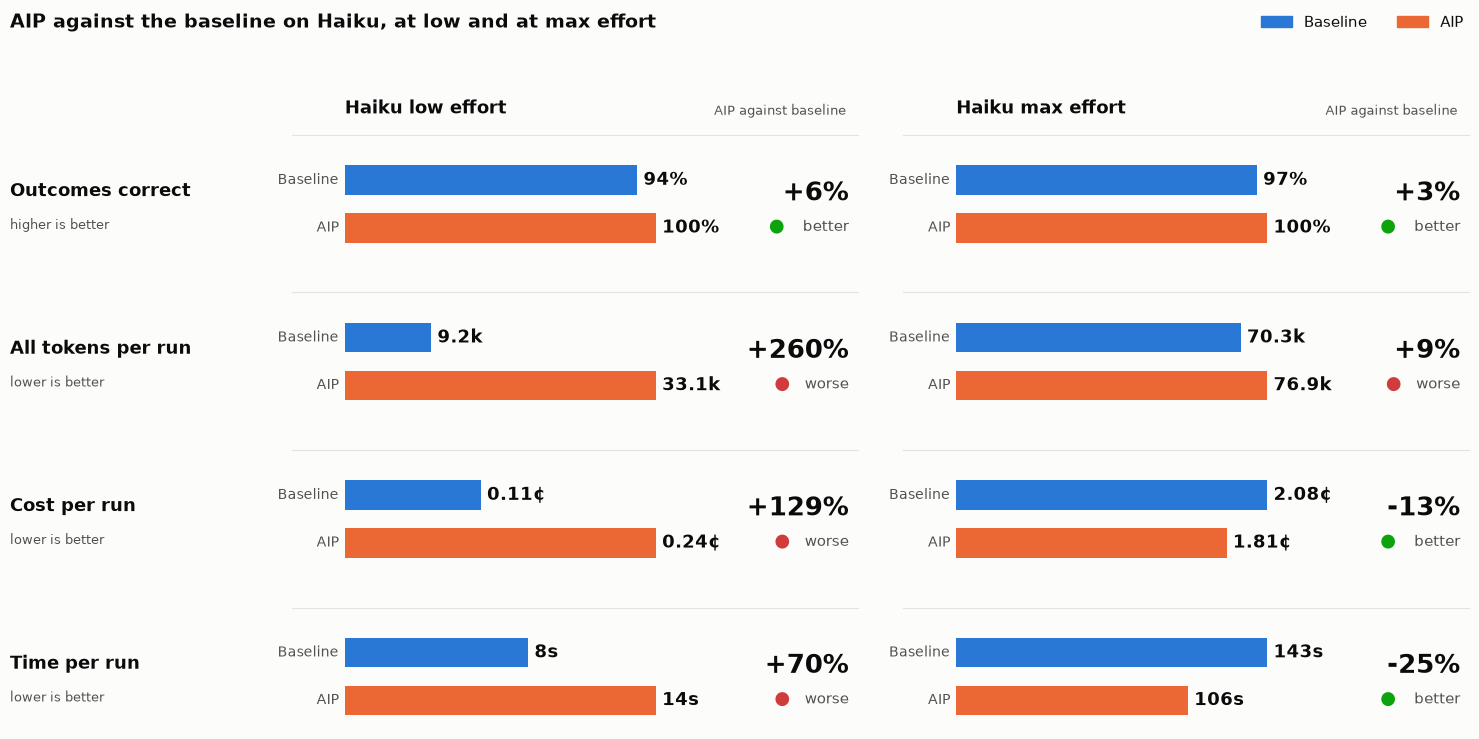

In [2]:
summary_figure([(f"{group} effort", pick(group, "Baseline"), pick(group, "AIP"), "Baseline", "AIP") for group in HAIKU],
               "AIP against the baseline on Haiku, at low and at max effort", "summary.png")

## 3. What was right

The share of runs that got each output wrong, over all thirty applications and then by tier. The two message charts use a strict scripted rubric, so read them as a rough guide.

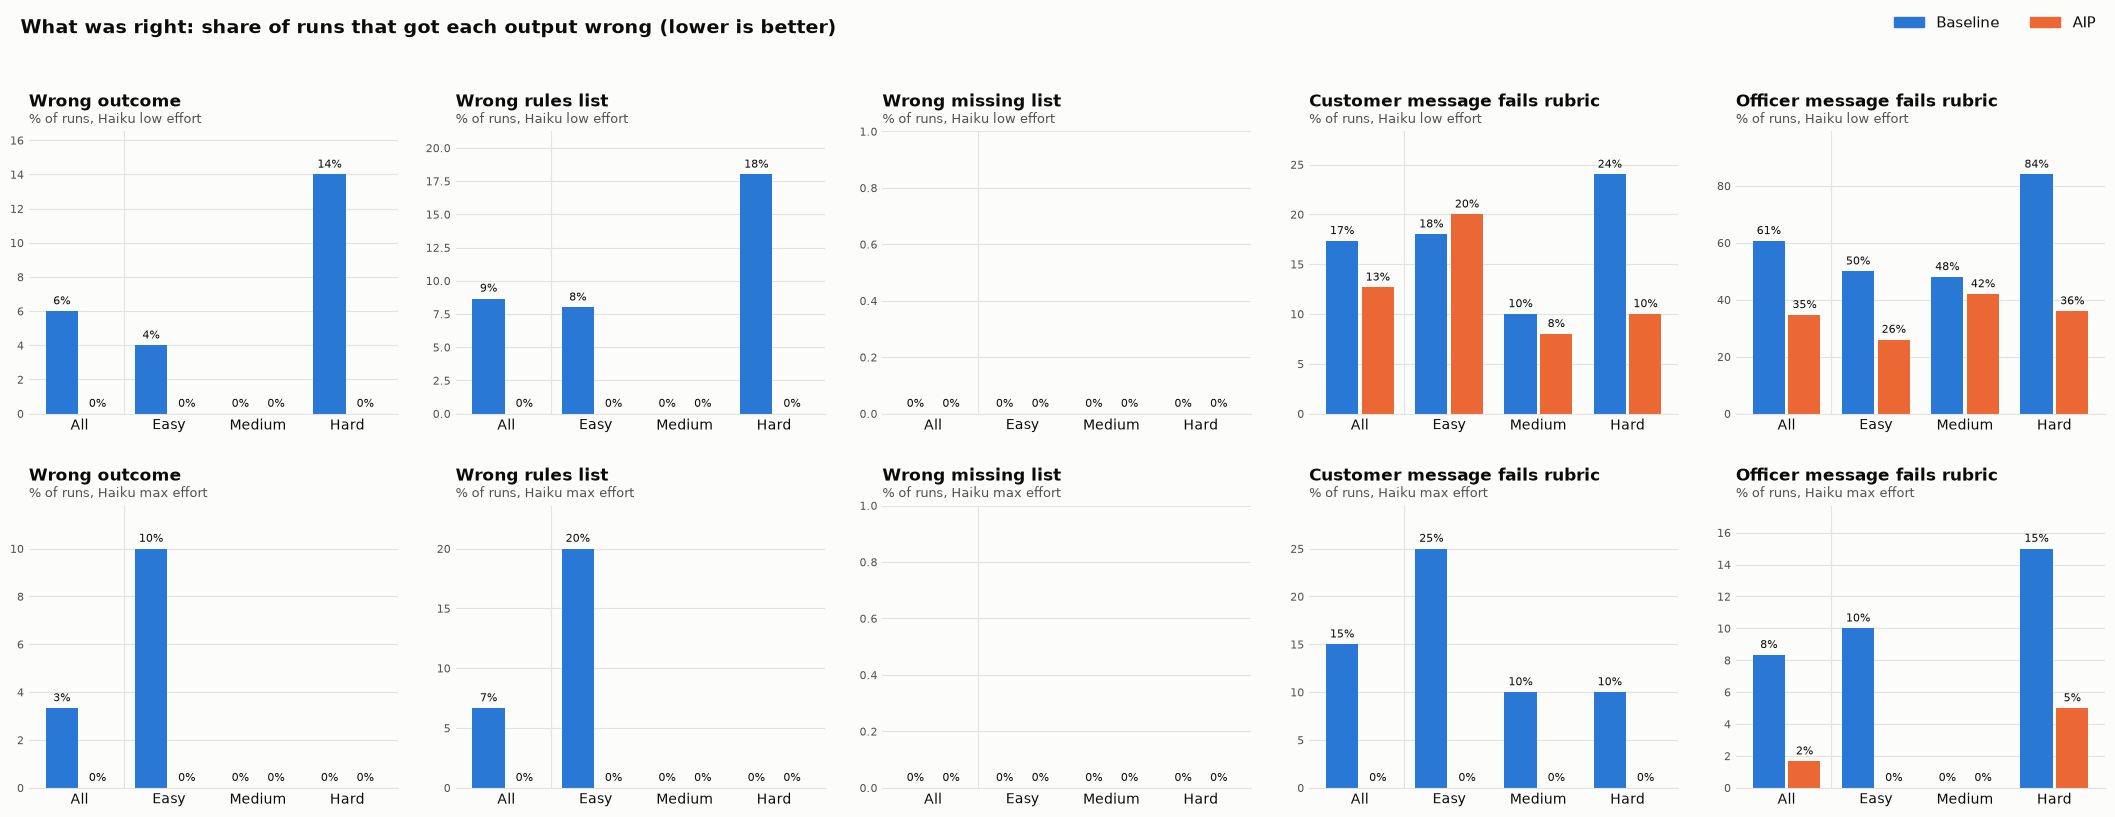

In [3]:
bar_figure(CORRECTNESS, "What was right: share of runs that got each output wrong (lower is better)", "correctness.png")

## 4. What it cost

Thinking tokens, all tokens, cost and time for each run.

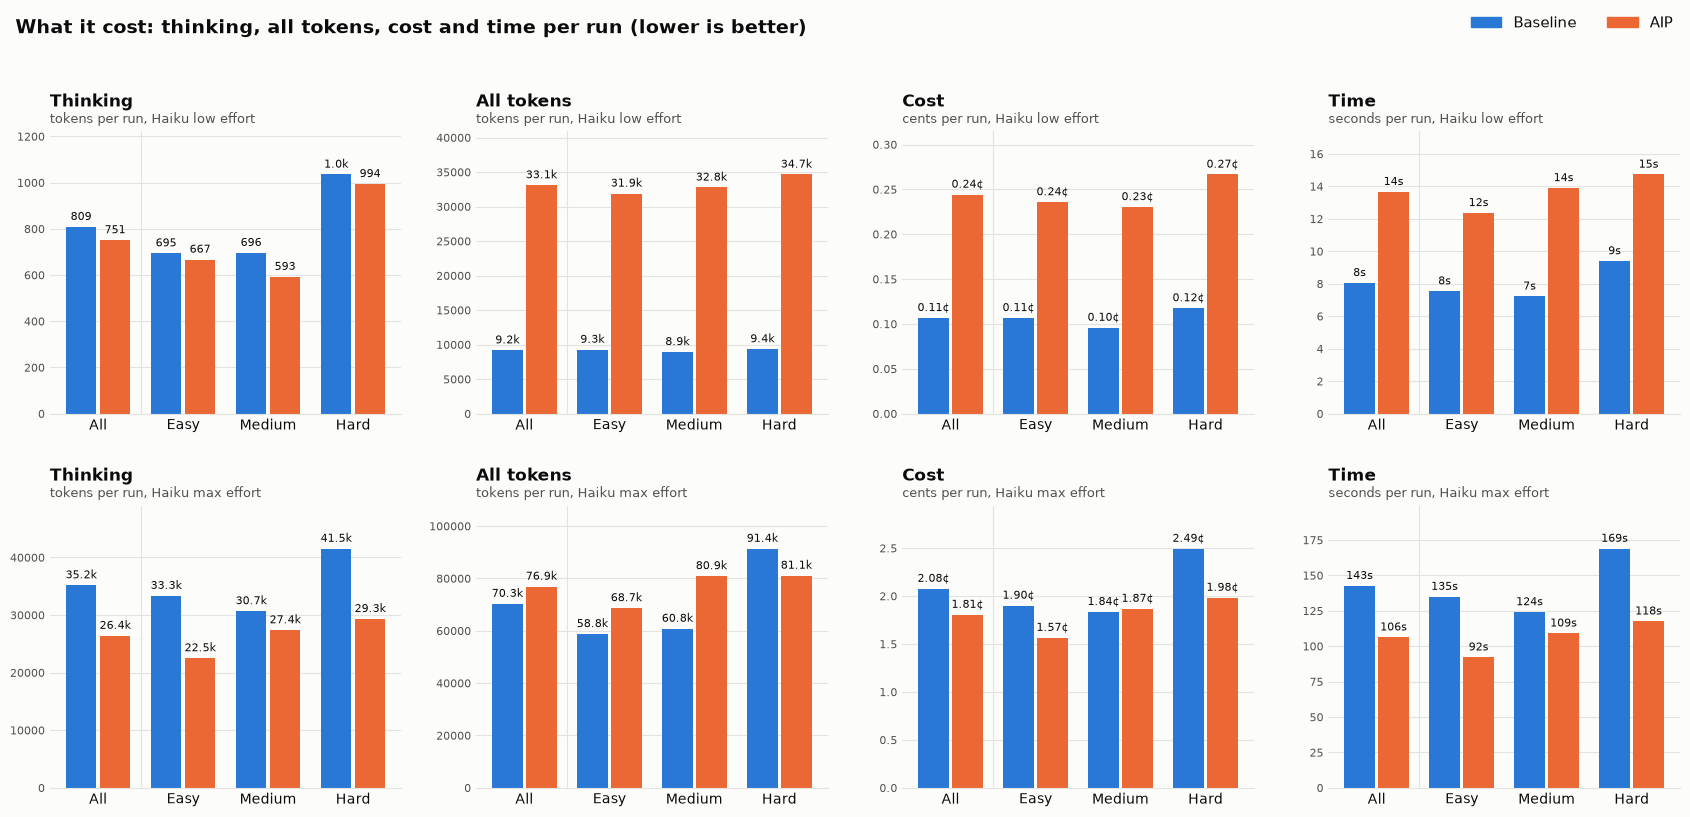

In [4]:
bar_figure(HEADLINE, "What it cost: thinking, all tokens, cost and time per run (lower is better)", "spend.png")

## 5. Where the tokens go

Every kind of token on one row for each effort, ending with the total. Each chart has its own scale.

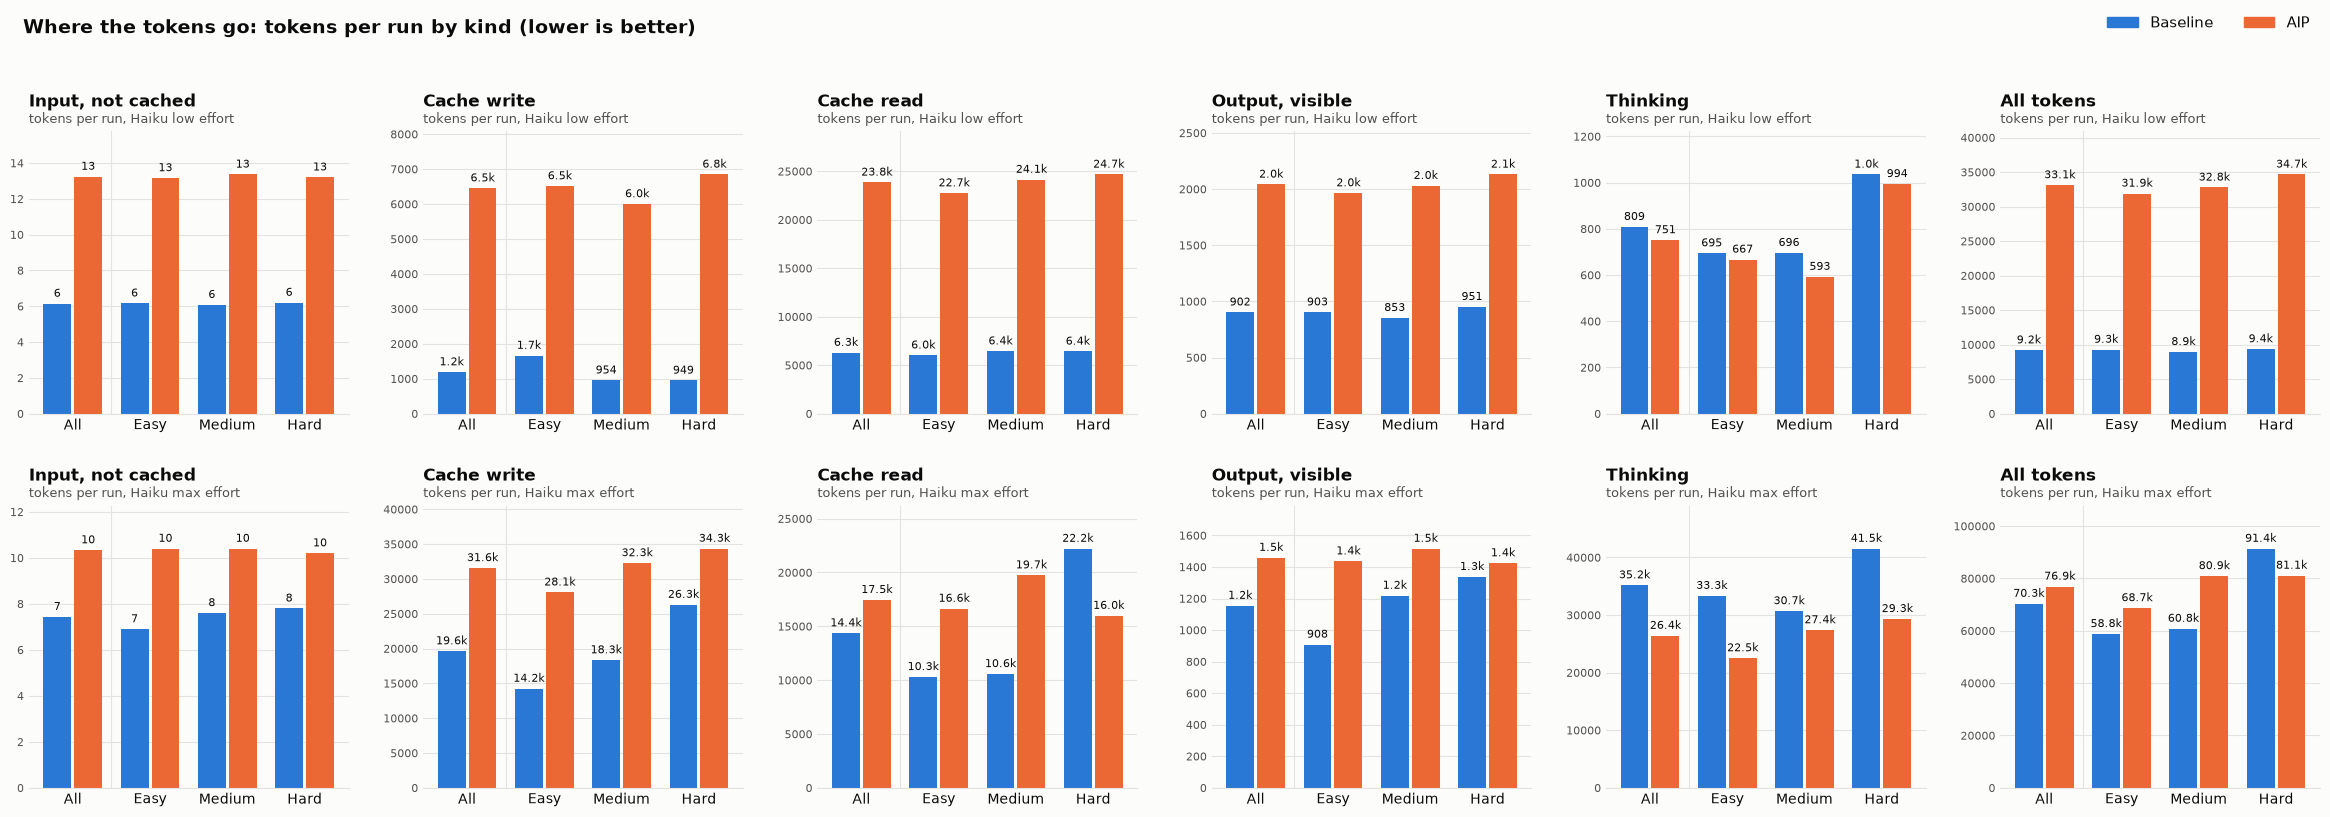

In [5]:
bar_figure(TOKENS, "Where the tokens go: tokens per run by kind (lower is better)", "tokens.png")

### What is happening

**At low effort, AIP adds context and removes nothing.**
- Neither arm thinks much: about 800 tokens each.
- The baseline reads three files and answers, in about 2 requests to the model. AIP calls the procedure's tools and makes 4 to 5, and each request re-reads the conversation so far from the cache.
- So cache writes are about 5 times the baseline's, cache reads about 4 times, visible output about double. All tokens: 3.6 times. Cost: 2.3 times.

**At max effort, AIP thinks less, and thinking is what costs.**
- The baseline thinks about 35,000 tokens a run to reach its decision. With AIP the procedure decides, and the agent thinks about 26,000: a quarter less.
- AIP still adds cached context, about 15,000 tokens a run.
- Net: 9% more tokens, 13% lower cost, 25% less time.

**Why more tokens costs less.** A token's price depends on its kind. AIP removes the dearest kind and adds the cheapest.

| Kind of token | Price per million | Against thinking |
|---|---|---|
| Thinking, and all other output | $0.50 | |
| Cache write | $0.125 | a quarter |
| Cache read | $0.01 | a fiftieth |

The two tables below are that trade, per run. The prices are recovered from the runs' reported costs. The decision model's calls are not Claude tokens and are not counted here.

In [6]:
for group in HAIKU:
    display(Markdown(f"**{group} effort**"))
    display(trade(group))

**Haiku low effort**

,"Tokens, AIP minus baseline",$ per 1M tokens,"Cost, AIP minus baseline"
"Input, not cached",+7,$0.100,+0.000¢
Cache write,"+5,264",$0.125,+0.066¢
Cache read,"+17,563",$0.010,+0.018¢
"Output, visible","+1,138",$0.500,+0.057¢
Thinking,-57,$0.500,-0.003¢
All tokens,"+23,915",,+0.137¢


**Haiku max effort**

,"Tokens, AIP minus baseline",$ per 1M tokens,"Cost, AIP minus baseline"
"Input, not cached",+3,$0.100,+0.000¢
Cache write,"+11,939",$0.125,+0.149¢
Cache read,"+3,095",$0.010,+0.003¢
"Output, visible",+304,$0.500,+0.015¢
Thinking,"-8,774",$0.500,-0.439¢
All tokens,"+6,567",,-0.271¢


## 6. Next: raising the model to match AIP

AIP on Haiku got every outcome right. Could a stronger model do the same with no procedure?

- **The run:** the baseline again, on **Sonnet at low effort**. Same thirty applications, same isolation, 5 runs of each (150 runs).
- **The comparison:** that baseline against **AIP on Haiku at low effort**, the cheapest AIP setting.

## 7. A stronger model, against a procedure on a cheaper one

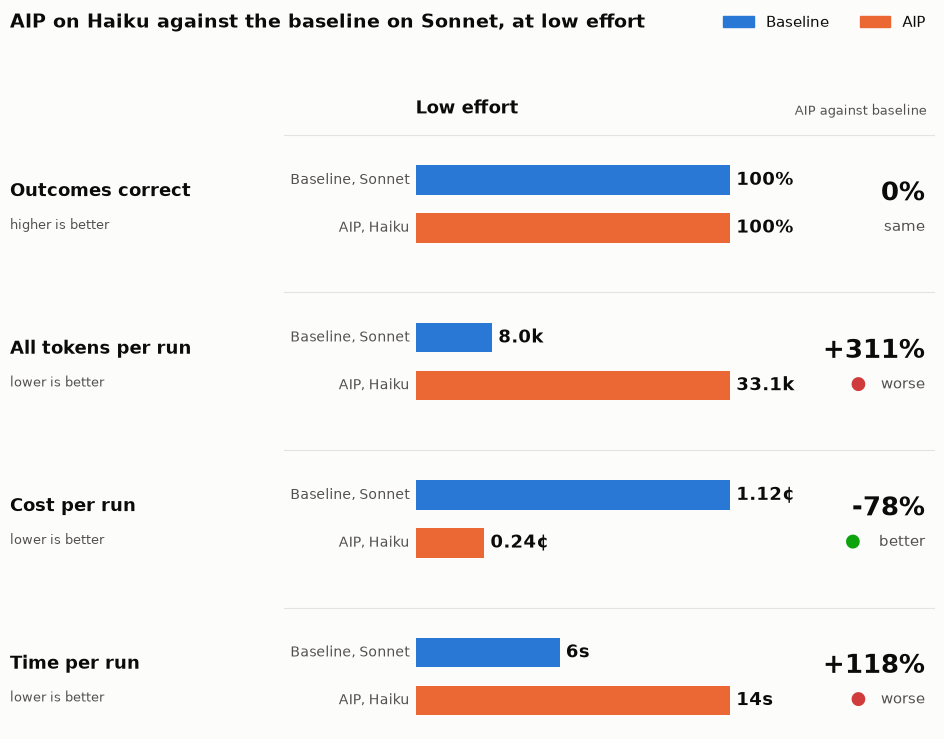

In [7]:
summary_figure([("Low effort", pick("Sonnet low", "Baseline"), pick("Haiku low", "AIP"), "Baseline, Sonnet", "AIP, Haiku")],
               "AIP on Haiku against the baseline on Sonnet, at low effort", "summary-sonnet.png")

---

## Appendix: the numbers behind the figures

In [8]:
def facts(part):
    return {"Runs": ("plain", len(part)), "Outcome correct": ("rate", part.outcome), "Rules list correct": ("rate", part.failed_rules),
            "Missing list correct": ("rate", part.missing),
            "Customer message passes rubric": ("rate", part.customer_message), "Officer message passes rubric": ("rate", part.officer_message),
            "Thinking tokens per run": ("count", part.tokens_thinking.mean()), "All tokens per run": ("count", part.tokens_total.mean()),
            "Cost per run": ("money", part.cost_exact.mean()), "Seconds per run": ("seconds", part.seconds.mean())}

def shown(kind, value):
    if kind == "rate":
        return share(value)
    return {"plain": f"{value}", "count": f"{value:,.0f}", "money": f"${value:.4f}", "seconds": f"{value:.1f}"}[kind]

def table(scope=None):
    out = {}
    for group, arm, _, _ in RUNS:
        f = facts(pick(group, arm, scope))
        out[(group, arm)] = {k: shown(*f[k]) for k in f}
    return pd.DataFrame(out)

display(Markdown("**Every arm, all thirty applications**"))
display(table())
for tier in TIERS:
    display(Markdown(f"**The {tier} tier**"))
    display(table(tier))

**Every arm, all thirty applications**

Haiku low                     Haiku max  \
                                      Baseline             AIP      Baseline   
Runs                                       150             150            60   
Outcome correct                  141/150 (94%)  150/150 (100%)   58/60 (97%)   
Rules list correct               137/150 (91%)  150/150 (100%)   56/60 (93%)   
Missing list correct            150/150 (100%)  150/150 (100%)  60/60 (100%)   
Customer message passes rubric   124/150 (83%)   131/150 (87%)   51/60 (85%)   
Officer message passes rubric     59/150 (39%)    98/150 (65%)   55/60 (92%)   
Thinking tokens per run                    809             751        35,186   
All tokens per run                       9,192          33,107        70,336   
Cost per run                           $0.0011         $0.0024       $0.0208   
Seconds per run                            8.1            13.7         142.6   

                                                  Sonnet low  
                                         AIP        Baseline  
Runs                                      60             150  
Outcome correct                 60/60 (100%)  150/150 (100%)  
Rules list correct              60/60 (100%)   145/150 (97%)  
Missing list correct            60/60 (100%)  150/150 (100%)  
Customer message passes rubric  60/60 (100%)   136/150 (91%)  
Officer message passes rubric    59/60 (98%)   131/150 (87%)  
Thinking tokens per run               26,413             120  
All tokens per run                    76,903           8,048  
Cost per run                         $0.0181         $0.0112  
Seconds per run                        106.3             6.3

**The easy tier**

Haiku low                   Haiku max  \
                                    Baseline           AIP      Baseline   
Runs                                      50            50            20   
Outcome correct                  48/50 (96%)  50/50 (100%)   18/20 (90%)   
Rules list correct               46/50 (92%)  50/50 (100%)   16/20 (80%)   
Missing list correct            50/50 (100%)  50/50 (100%)  20/20 (100%)   
Customer message passes rubric   41/50 (82%)   40/50 (80%)   15/20 (75%)   
Officer message passes rubric    25/50 (50%)   37/50 (74%)   18/20 (90%)   
Thinking tokens per run                  695           667        33,340   
All tokens per run                     9,277        31,897        58,799   
Cost per run                         $0.0011       $0.0024       $0.0190   
Seconds per run                          7.5          12.4         134.9   

                                                Sonnet low  
                                         AIP      Baseline  
Runs                                      20            50  
Outcome correct                 20/20 (100%)  50/50 (100%)  
Rules list correct              20/20 (100%)   45/50 (90%)  
Missing list correct            20/20 (100%)  50/50 (100%)  
Customer message passes rubric  20/20 (100%)   45/50 (90%)  
Officer message passes rubric   20/20 (100%)   48/50 (96%)  
Thinking tokens per run               22,523            82  
All tokens per run                    68,683         7,922  
Cost per run                         $0.0157       $0.0111  
Seconds per run                         92.2           5.8

**The medium tier**

Haiku low                   Haiku max  \
                                    Baseline           AIP      Baseline   
Runs                                      50            50            20   
Outcome correct                 50/50 (100%)  50/50 (100%)  20/20 (100%)   
Rules list correct              50/50 (100%)  50/50 (100%)  20/20 (100%)   
Missing list correct            50/50 (100%)  50/50 (100%)  20/20 (100%)   
Customer message passes rubric   45/50 (90%)   46/50 (92%)   18/20 (90%)   
Officer message passes rubric    26/50 (52%)   29/50 (58%)  20/20 (100%)   
Thinking tokens per run                  696           593        30,688   
All tokens per run                     8,944        32,772        60,819   
Cost per run                         $0.0010       $0.0023       $0.0184   
Seconds per run                          7.2          13.9         124.1   

                                                Sonnet low  
                                         AIP      Baseline  
Runs                                      20            50  
Outcome correct                 20/20 (100%)  50/50 (100%)  
Rules list correct              20/20 (100%)  50/50 (100%)  
Missing list correct            20/20 (100%)  50/50 (100%)  
Customer message passes rubric  20/20 (100%)   46/50 (92%)  
Officer message passes rubric   20/20 (100%)   48/50 (96%)  
Thinking tokens per run               27,382           114  
All tokens per run                    80,927         7,919  
Cost per run                         $0.0187       $0.0105  
Seconds per run                        109.1           5.9

**The hard tier**

Haiku low                   Haiku max  \
                                    Baseline           AIP      Baseline   
Runs                                      50            50            20   
Outcome correct                  43/50 (86%)  50/50 (100%)  20/20 (100%)   
Rules list correct               41/50 (82%)  50/50 (100%)  20/20 (100%)   
Missing list correct            50/50 (100%)  50/50 (100%)  20/20 (100%)   
Customer message passes rubric   38/50 (76%)   45/50 (90%)   18/20 (90%)   
Officer message passes rubric     8/50 (16%)   32/50 (64%)   17/20 (85%)   
Thinking tokens per run                1,035           994        41,532   
All tokens per run                     9,354        34,653        91,389   
Cost per run                         $0.0012       $0.0027       $0.0249   
Seconds per run                          9.4          14.7         168.9   

                                                Sonnet low  
                                         AIP      Baseline  
Runs                                      20            50  
Outcome correct                 20/20 (100%)  50/50 (100%)  
Rules list correct              20/20 (100%)  50/50 (100%)  
Missing list correct            20/20 (100%)  50/50 (100%)  
Customer message passes rubric  20/20 (100%)   45/50 (90%)  
Officer message passes rubric    19/20 (95%)   35/50 (70%)  
Thinking tokens per run               29,333           163  
All tokens per run                    81,099         8,303  
Cost per run                         $0.0198       $0.0120  
Seconds per run                        117.6           7.0

In [9]:
def wrong_answers():
    rows = []
    for (group, arm, application), part in runs.groupby(["group", "arm", "application"]):
        if part.decided.all():
            continue
        answers = (part.got + " [" + part.got_failed_rules + "]").value_counts()
        want = EXPECTED[application]
        rows.append({"runs": group, "arm": arm, "application": application, "tier": want["difficulty"],
                     "expected": f"{want['outcome']} [{' '.join(want['failed_rules'])}]",
                     "answers given": ";  ".join(f"{a} x{n}" for a, n in answers.items())})
    return pd.DataFrame(rows).set_index(["runs", "arm", "application"])

display(Markdown("**Every application an arm got wrong at least once, and the answers it gave**"))
display(wrong_answers())

**Every application an arm got wrong at least once, and the answers it gave**

tier       expected  \
runs       arm      application                        
Haiku low  Baseline APP-2001     easy     approve []   
                    APP-2004     easy  escalate [J1]   
                    APP-2005     easy  escalate [J3]   
                    APP-2201     hard     approve []   
                    APP-2209     hard  escalate [J1]   
                    APP-2210     hard     approve []   
Haiku max  Baseline APP-2001     easy     approve []   
                    APP-2005     easy  escalate [J3]   
Sonnet low Baseline APP-2008     easy  escalate [J2]   

                                                          answers given  
runs       arm      application                                          
Haiku low  Baseline APP-2001           approve [] x3;  escalate [J3] x2  
                    APP-2004     escalate [J1] x4;  escalate [J1 J2] x1  
                    APP-2005     escalate [J3] x4;  escalate [J3 J5] x1  
                    APP-2201           approve [] x3;  escalate [J3] x2  
                    APP-2209     escalate [J1] x3;  escalate [J1 J2] x2  
                    APP-2210                           escalate [J3] x5  
Haiku max  Baseline APP-2001                           escalate [J3] x2  
                    APP-2005                        escalate [J3 J5] x2  
Sonnet low Baseline APP-2008                        escalate [J1 J2] x5

In [10]:
display(Markdown("**Price per million tokens, recovered from the Haiku runs' reported costs**"))
display(pd.DataFrame({"$ per 1M tokens": {TYPES[k]: f"${PRICE[k] * 1e6:,.3f}" for k in TYPES}}))
print(f"Largest gap between a run's reported cost and its cost at these prices: ${FIT_ERROR:.6f}")

def by_kind():
    out = {}
    for group, arm, _, _ in RUNS:
        part = pick(group, arm)
        out[(group, arm)] = {**{name: f"{part[column].mean():,.0f}" for column, name in TYPES.items()},
                             "All tokens": f"{part.tokens_total.mean():,.0f}", "Requests' cost per run": f"{part.cost_exact.mean() * 100:.3f}¢"}
    return pd.DataFrame(out)

display(Markdown("**Tokens per run by kind**"))
display(by_kind())

**Price per million tokens, recovered from the Haiku runs' reported costs**

,$ per 1M tokens
"Input, not cached",$0.100
Cache write,$0.125
Cache read,$0.010
"Output, visible",$0.500
Thinking,$0.500


Largest gap between a run's reported cost and its cost at these prices: $0.000000


**Tokens per run by kind**

Haiku low         Haiku max         Sonnet low
                        Baseline     AIP  Baseline     AIP   Baseline
Input, not cached              6      13         7      10          6
Cache write                1,188   6,452    19,624  31,563        852
Cache read                 6,287  23,850    14,363  17,458      6,347
Output, visible              902   2,041     1,155   1,459        723
Thinking                     809     751    35,186  26,413        120
All tokens                 9,192  33,107    70,336  76,903      8,048
Requests' cost per run    0.107¢  0.244¢    2.077¢  1.806¢     1.120¢